# Ánh xạ đặc trưng và thủ thuật kernel

*Bài 7, mục 7.1.3.* Dữ liệu không tách được tuyến tính trong không gian gốc có thể tách được sau khi ánh xạ sang không gian nhiều chiều hơn bằng hàm $\phi(\mathbf{x})$. Bài toán đối ngẫu của SVM chỉ cần tích vô hướng $\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)$, nên chỉ cần một **hàm kernel** $K(\mathbf{x}_i, \mathbf{x}_j) = \phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)$ mà không phải tính $\phi$ tường minh.

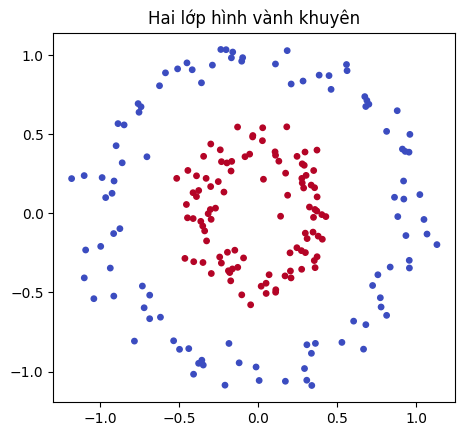

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X, y = make_circles(n_samples=200, factor=0.4, noise=0.08, random_state=0)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=15)
plt.gca().set_aspect('equal'); plt.title('Hai lớp hình vành khuyên')
plt.show()

## 1. SVM tuyến tính thất bại trên dữ liệu gốc

In [2]:
linear_svm = SVC(kernel='linear', C=1).fit(X, y)
print('SVM tuyến tính, độ chính xác huấn luyện: %.3f' % linear_svm.score(X, y))

SVM tuyến tính, độ chính xác huấn luyện: 0.620


## 2. Ánh xạ tường minh $\phi(x_1, x_2) = (x_1, x_2, x_1^2 + x_2^2)$

Thêm chiều thứ ba là bình phương khoảng cách tới gốc tọa độ: lớp trong có giá trị nhỏ, lớp ngoài có giá trị lớn, nên một mặt phẳng nằm ngang tách được hai lớp.

In [3]:
def phi(X):
    return np.column_stack([X[:, 0], X[:, 1], X[:, 0]**2 + X[:, 1]**2])


Z = phi(X)
svm_3d = SVC(kernel='linear', C=1).fit(Z, y)
print('SVM tuyến tính trong không gian 3 chiều, độ chính xác: %.3f' % svm_3d.score(Z, y))
print('w =', svm_3d.coef_[0].round(3), ' b = %.3f' % svm_3d.intercept_[0])

SVM tuyến tính trong không gian 3 chiều, độ chính xác: 1.000
w = [-0.06   0.178 -4.06 ]  b = 2.100


Thành phần thứ ba của $\mathbf{w}$ chiếm ưu thế: siêu phẳng gần như là $x_1^2 + x_2^2 = r^2$, tức một **đường tròn** trong không gian gốc.

## 3. Kernel đa thức: tính tích vô hướng mà không cần $\phi$

Với $\phi(\mathbf{x}) = (x_1^2, \sqrt{2}x_1x_2, x_2^2)$ ta có $\phi(\mathbf{x})^T\phi(\mathbf{z}) = (\mathbf{x}^T\mathbf{z})^2$.

In [4]:
def phi_poly(x):
    return np.array([x[0]**2, np.sqrt(2) * x[0] * x[1], x[1]**2])


x = np.array([1.0, 2.0])
z = np.array([3.0, 1.0])
print('phi(x)^T phi(z) = %.4f' % (phi_poly(x) @ phi_poly(z)))
print('(x^T z)^2       = %.4f' % ((x @ z)**2))

phi(x)^T phi(z) = 25.0000
(x^T z)^2       = 25.0000


Kernel đa thức bậc $p$: $K(\mathbf{x}, \mathbf{z}) = (\gamma\,\mathbf{x}^T\mathbf{z} + r)^p$. Với $d$ đặc trưng và bậc $p$, số chiều của $\phi$ tăng rất nhanh, nhưng tính kernel vẫn chỉ tốn $O(d)$:

In [5]:
from math import comb

for d, p in [(2, 2), (10, 3), (100, 3), (784, 4)]:
    print('d = %3d, bậc p = %d: số đơn thức bậc <= p là %s' % (d, p, f'{comb(d + p, p):,}'))

d =   2, bậc p = 2: số đơn thức bậc <= p là 6
d =  10, bậc p = 3: số đơn thức bậc <= p là 286
d = 100, bậc p = 3: số đơn thức bậc <= p là 176,851
d = 784, bậc p = 4: số đơn thức bậc <= p là 15,943,435,565


## 4. Kernel RBF (Gauss)

$K(\mathbf{x}, \mathbf{z}) = \exp(-\gamma\|\mathbf{x} - \mathbf{z}\|^2)$ đo **độ tương đồng**: bằng 1 khi hai điểm trùng nhau, giảm dần về 0 khi hai điểm xa nhau. Không gian đặc trưng tương ứng có vô số chiều.

In [6]:
def rbf_kernel(x, z, gamma):
    return np.exp(-gamma * np.sum((x - z)**2))


for distance in [0, 0.5, 1, 2, 3]:
    x, z = np.zeros(2), np.array([distance, 0.0])
    print('||x - z|| = %.1f:  K (gamma=0.5) = %.4f,  K (gamma=5) = %.4f'
          % (distance, rbf_kernel(x, z, 0.5), rbf_kernel(x, z, 5)))

||x - z|| = 0.0:  K (gamma=0.5) = 1.0000,  K (gamma=5) = 1.0000
||x - z|| = 0.5:  K (gamma=0.5) = 0.8825,  K (gamma=5) = 0.2865
||x - z|| = 1.0:  K (gamma=0.5) = 0.6065,  K (gamma=5) = 0.0067
||x - z|| = 2.0:  K (gamma=0.5) = 0.1353,  K (gamma=5) = 0.0000
||x - z|| = 3.0:  K (gamma=0.5) = 0.0111,  K (gamma=5) = 0.0000


## 5. SVM với kernel trên dữ liệu gốc

In [7]:
for kernel, params in [('poly', {'degree': 2, 'coef0': 1}), ('rbf', {'gamma': 1})]:
    svm = SVC(kernel=kernel, C=1, **params).fit(X, y)
    print('kernel = %-4s: độ chính xác %.3f, %d vector hỗ trợ' % (kernel, svm.score(X, y), len(svm.support_)))

kernel = poly: độ chính xác 1.000, 17 vector hỗ trợ
kernel = rbf : độ chính xác 1.000, 34 vector hỗ trợ


Hàm quyết định của SVM với kernel: $f(\mathbf{x}) = \sum_{i \in \mathcal{S}} \lambda_i y_i K(\mathbf{x}_i, \mathbf{x}) + b$. Kiểm tra lại bằng cách tự tính:

In [8]:
svm = SVC(kernel='rbf', gamma=1, C=1).fit(X, y)
x_new = np.array([0.1, 0.2])
manual = sum(coef * rbf_kernel(sv, x_new, 1) for coef, sv in zip(svm.dual_coef_[0], svm.support_vectors_)) + svm.intercept_[0]
print('Tự tính f(x) = %.4f' % manual)
print('decision_function = %.4f' % svm.decision_function([x_new])[0])

Tự tính f(x) = 2.0209
decision_function = 2.0209
